# 6B — Regression · NYC Yellow Taxi Demand 2026
**Penanggung jawab:** Mufid Dhamarjati Kusuma · Fase 6B (P11)  
**Model:** Linear Regression, Ridge, Lasso · **Target:** `target_pickup_count` · **Baseline:** lag 168 jam.

Notebook ini **tidak membuat ulang agregasi atau fitur**. Masukan resmi: `datasets/interim/2026/features_dataset.parquet` dari Anggota 1. Output disimpan di `out/regression/`.

**Penting:** Pada dataset tim, kolom `hour` menandai jam **T** yang diprediksi dan fitur lag dihitung sebelum T. Jadi prediksi untuk T ekuivalen dengan forecast **t+1** dari akhir jam sebelumnya. Pembagian **train Jan–Apr, validation Mei, test Juni**. Juni tidak disentuh hingga pemilihan model akhir dan persetujuan tim.


## 0. Persiapan, path, dan konfigurasi

In [1]:
from pathlib import Path
import sys, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_absolute_error
from sklearn.base import clone

# Notebook dijalankan dari script/ maupun root repository.
ROOT = Path.cwd().resolve()
if not (ROOT / 'datasets').exists(): ROOT = ROOT.parent
assert (ROOT / 'datasets').exists(), f'Folder datasets/ tidak ditemukan dari {Path.cwd()}'
sys.path.insert(0, str(ROOT / 'script' / 'tools'))
import metrics  # fungsi metrik bersama milik tim
DATA_FILE = ROOT / 'datasets/interim/2026/features_dataset.parquet'
OUT = ROOT / 'out/regression'
OUT.mkdir(parents=True, exist_ok=True)
SEED = 42
ALPHA_RIDGE = 10.0     # nilai awal, bukan hasil tuning
ALPHA_LASSO = 0.1      # nilai awal, bukan hasil tuning
COBA_LOG1P = True      # hanya bila target >= 0; bandingkan pada skala asli
PAKAI_TEST_FINAL = False  # sengaja False; aktifkan SETELAH model final diputuskan tim
np.random.seed(SEED)
sns.set_theme(style='whitegrid')
print('ROOT:', ROOT, '\nInput:', DATA_FILE, '\nOutput:', OUT)


ROOT: C:\Users\hp\Documents\25_IF-C_Cooked_pake_d 
Input: C:\Users\hp\Documents\25_IF-C_Cooked_pake_d\datasets\interim\2026\features_dataset.parquet 
Output: C:\Users\hp\Documents\25_IF-C_Cooked_pake_d\out\regression


## 1. Membaca dan memvalidasi dataset fitur

In [2]:
if not DATA_FILE.is_file():
    raise FileNotFoundError(f'{DATA_FILE} belum ada. Jalankan Fase 4A dan Fase 5 terlebih dahulu.')
cols_needed = ['hour','zone_id','PU_borough','target_pickup_count','split','lag_168']
data = pd.read_parquet(DATA_FILE)
missing = sorted(set(cols_needed) - set(data.columns))
assert not missing, f'Kolom wajib tidak tersedia: {missing}'
data['hour'] = pd.to_datetime(data['hour'])
data['split'] = data['split'].astype(str).str.lower()
assert set(data['split'].unique()) <= {'train','validation','test'}
assert not data.duplicated(['zone_id','hour']).any(), 'Ada duplikat zona-jam!'
assert not data['target_pickup_count'].isna().any(), 'Target kosong; cek DST dan cleaning'
assert (data['target_pickup_count'] >= 0).all(), 'Target pickup tidak boleh negatif'
assert data.loc[data.split=='train','hour'].max() < data.loc[data.split=='validation','hour'].min()
assert data.loc[data.split=='validation','hour'].max() < data.loc[data.split=='test','hour'].min()
train = data[data.split=='train'].sort_values(['hour','zone_id']).copy()
val = data[data.split=='validation'].sort_values(['hour','zone_id']).copy()
# test belum dimasukkan ke evaluasi; keberadaannya hanya dicek pada schema dan batas split
assert len(train) and len(val)
print('Ukuran train:', len(train), 'validation:', len(val))
print('Waktu train:', train.hour.min(), '-', train.hour.max())
print('Waktu validation:', val.hour.min(), '-', val.hour.max())
print('Nol pada target training:', f'{(train.target_pickup_count==0).mean():.2%}')
print('Skewness target train:', round(train.target_pickup_count.skew(),3))


Ukuran train: 668809 validation: 195672
Waktu train: 2026-01-08 00:00:00 - 2026-04-30 23:00:00
Waktu validation: 2026-05-01 00:00:00 - 2026-05-31 23:00:00
Nol pada target training: 37.91%
Skewness target train: 4.784


## 2. Fitur, preprocessing, dan pengamanan leakage

In [3]:
NUMERIC = ['hour_of_day','day_of_week','month','is_weekend','is_holiday','is_major_nyc_event',
           'PU_longitude','PU_latitude','is_airport','is_cbd',
           'lag_1','lag_24','lag_168','roll_24','roll_168']
CATEGORICAL = ['PU_borough']
TARGET = 'target_pickup_count'
FITUR = NUMERIC + CATEGORICAL
assert not set(FITUR) - set(data.columns), f'Fitur belum tersedia: {set(FITUR)-set(data.columns)}'
DILARANG = {'DO_longitude','DO_latitude','fare_amount','total_amount','trip_distance',
            'tip_amount','cbd_congestion_fee','passenger_count',TARGET,'demand_level','split','hour'}
assert not (set(FITUR) & DILARANG), 'Fitur berpotensi leakage'
assert train[FITUR+[TARGET,'lag_168']].notna().all().all(), 'NaN pada train'
assert val[FITUR+[TARGET,'lag_168']].notna().all().all(), 'NaN pada validation'
# OneHotEncoder dan StandardScaler di-fit HANYA menggunakan data training.
def preprocessor():
    return ColumnTransformer([
        ('num', StandardScaler(), NUMERIC),
        ('borough', OneHotEncoder(handle_unknown='ignore'), CATEGORICAL),
    ], remainder='drop', sparse_threshold=0.0)

X_train, y_train = train[FITUR], train[TARGET].to_numpy(dtype=float)
X_val, y_val = val[FITUR], val[TARGET].to_numpy(dtype=float)
# MASE scale sesuai baseline dan definisi script/tools/metrics.py
SCALE_MASE = metrics.mase_scale(y_train, train['lag_168'].to_numpy())
print('MASE scale training:', SCALE_MASE)


MASE scale training: 5.079486071509205


## 3. Baseline seasonal naive (validation)

In [4]:
def eval_metrik(y, pred):
    pred = np.maximum(np.asarray(pred, dtype=float), 0) # Jumlah pickup tidak negatif
    return metrics.regression_metrics(y, pred, scale=SCALE_MASE)

baseline_pred = val['lag_168'].to_numpy(dtype=float)
base_result = eval_metrik(y_val, baseline_pred)
print(pd.Series(base_result).round(4).to_string())


mae      5.2773
rmse    16.0275
wape     0.2582
r2       0.9206
mase     1.0390


## 4. Training Linear Regression, Ridge, dan Lasso (+ opsi log1p)

In [5]:
MODEL_SPECS = {
    'Linear': LinearRegression(),
    'Ridge': Ridge(alpha=ALPHA_RIDGE, random_state=SEED),
    'Lasso': Lasso(alpha=ALPHA_LASSO, max_iter=2500, tol=1e-3, selection='cyclic'),
}

# Log-target hanya uji tambahan ketika zero-inflated / miring; invers expm1 saat evaluasi.
def make_model(base, log_target=False):
    pipe = Pipeline([('preprocess', preprocessor()), ('model', clone(base))])
    if log_target:
        return TransformedTargetRegressor(regressor=pipe, func=np.log1p, inverse_func=np.expm1, check_inverse=False)
    return pipe

hasil = [{'model':'Seasonal Naive (lag168)','transformasi':'asli','periode':'validation',
          **base_result, 'train_seconds':0.0, 'predict_seconds':0.0}]
model_tersimpan = {}
prediksi = {'Seasonal Naive (lag168)': np.maximum(baseline_pred,0)}
for nama, estimator in MODEL_SPECS.items():
    for log_flag in ([False,True] if COBA_LOG1P else [False]):
        key = nama + ('_log1p' if log_flag else '')
        model = make_model(estimator, log_flag)
        t0 = time.perf_counter()
        with warnings.catch_warnings(record=True) as warn_list:
            warnings.simplefilter('always')
            model.fit(X_train,y_train)
        dur_train = time.perf_counter()-t0
        t1 = time.perf_counter()
        pred = np.maximum(model.predict(X_val),0)
        dur_pred = time.perf_counter()-t1
        skor = eval_metrik(y_val,pred)
        hasil.append({'model':key,'transformasi':'log1p' if log_flag else 'asli',
                      'periode':'validation',**skor,'train_seconds':dur_train,'predict_seconds':dur_pred})
        model_tersimpan[key] = model
        prediksi[key] = pred
        print(f'{key:17} MAE={skor["mae"]:.3f} RMSE={skor["rmse"]:.3f} WAPE={skor["wape"]:.3f} MASE={skor["mase"]:.3f} waktu={dur_train:.1f}s')
        if warn_list: print('  Peringatan training:', '; '.join(sorted(set(str(w.message)[:160] for w in warn_list)))[:300])
metrik_val = pd.DataFrame(hasil).sort_values('mae')
display(metrik_val.round(4))
metrik_val.to_csv(OUT/'06b_metrics_validation.csv',index=False)


Linear            MAE=4.164 RMSE=11.605 WAPE=0.204 MASE=0.820 waktu=2.7s
Linear_log1p      MAE=90.731 RMSE=2002.703 WAPE=4.439 MASE=17.862 waktu=1.8s
Ridge             MAE=4.164 RMSE=11.605 WAPE=0.204 MASE=0.820 waktu=1.4s
Ridge_log1p       MAE=90.784 RMSE=2004.147 WAPE=4.442 MASE=17.873 waktu=1.1s
Lasso             MAE=4.156 RMSE=11.651 WAPE=0.203 MASE=0.818 waktu=3.7s
Lasso_log1p       MAE=60.763 RMSE=1229.360 WAPE=2.973 MASE=11.962 waktu=2.1s


,model,transformasi,periode,mae,rmse,wape,r2,mase,train_seconds,predict_seconds
5,Lasso,asli,validation,4.1556,11.6513,0.2033,0.9580,0.8181,3.7229,0.1074
3,Ridge,asli,validation,4.1636,11.6049,0.2037,0.9584,0.8197,1.3875,0.1749
1,Linear,asli,validation,4.1636,11.6050,0.2037,0.9584,0.8197,2.7228,0.2157
0,Seasonal Naive (lag168),asli,validation,5.2773,16.0275,0.2582,0.9206,1.0390,0.0000,0.0000
6,Lasso_log1p,log1p,validation,60.7626,1229.3596,2.9730,-466.0968,11.9624,2.1194,0.1456
2,Linear_log1p,log1p,validation,90.7306,2002.7029,4.4393,-1238.6014,17.8622,1.7788,0.2350
4,Ridge_log1p,log1p,validation,90.7843,2004.1471,4.4420,-1240.3898,17.8727,1.0927,0.1674


## 5. Train vs validation: overfitting / underfitting

In [6]:
err_rows=[]
for name, model in model_tersimpan.items():
    t0=time.perf_counter()
    p_train=np.maximum(model.predict(X_train),0)
    p_val=prediksi[name]
    err_rows.append({'model':name,'mae_train':mean_absolute_error(y_train,p_train),
                     'mae_validation':mean_absolute_error(y_val,p_val),
                     'gap_mae':mean_absolute_error(y_val,p_val)-mean_absolute_error(y_train,p_train),
                     'predict_train_seconds':time.perf_counter()-t0})
gap=pd.DataFrame(err_rows).sort_values('mae_validation')
display(gap.round(3))
gap.to_csv(OUT/'06b_train_validation_gap.csv', index=False)


,model,mae_train,mae_validation,gap_mae,predict_train_seconds
4,Lasso,4.124,4.156,0.031,0.475
2,Ridge,4.157,4.164,0.007,0.628
0,Linear,4.157,4.164,0.007,0.538
5,Lasso_log1p,39.485,60.763,21.278,0.488
1,Linear_log1p,58.449,90.731,32.282,0.434
3,Ridge_log1p,58.474,90.784,32.310,0.534


## 6. Analisis residual dan perbedaan performa zona

,kategori,jumlah_observasi,batas_rata_rata_training,mae,rmse,wape,r2,mase
0,Ramai,97464,1.6748,7.7571,16.4755,0.1919,0.9524,1.5271
1,Sepi,98208,1.6748,0.5814,1.0447,0.9504,0.3090,0.1145


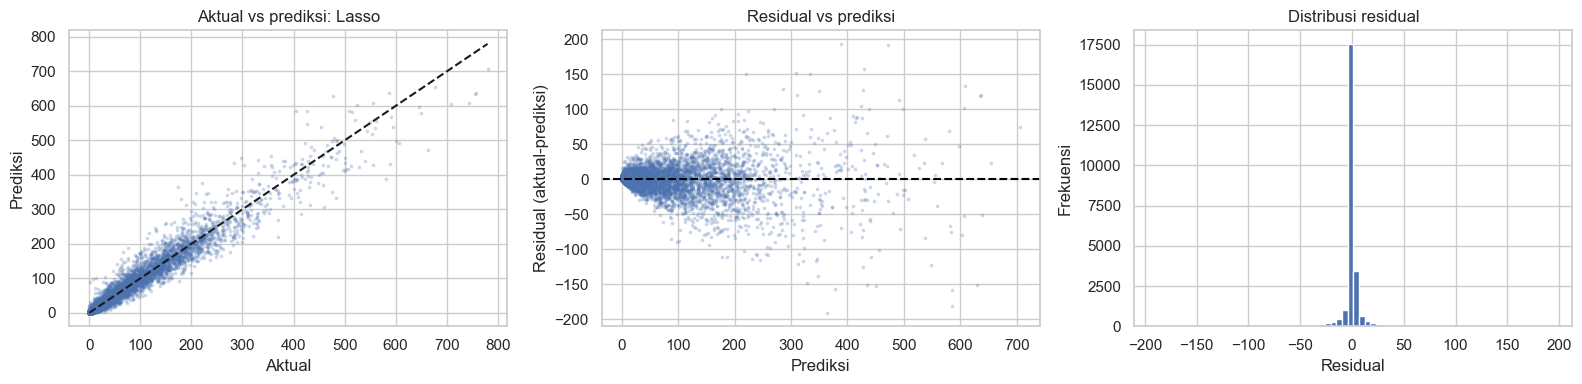

Residual mean: -0.242 MAE validation: 4.156


In [7]:
# Pilih model dengan MAE validation terbaik (belum test dan belum tuning).
best_name = metrik_val.loc[metrik_val['model']!='Seasonal Naive (lag168)'].iloc[0]['model']
best_model = model_tersimpan[best_name]
val_pred = prediksi[best_name]
residual = y_val - val_pred
pred_out = val[['hour','zone_id','PU_zone_name','PU_borough',TARGET,'lag_168']].copy() if 'PU_zone_name' in val else val[['hour','zone_id','PU_borough',TARGET,'lag_168']].copy()
pred_out['prediction'] = val_pred
pred_out['residual'] = residual
pred_out['abs_error'] = abs(residual)
pred_out.to_parquet(OUT/'06b_predictions_validation.parquet',index=False)

# Kategori ramai/sepi ditetapkan berdasarkan rata-rata pickup pada data TRAINING saja.
mean_by_zone = train.groupby('zone_id')[TARGET].mean()
threshold = mean_by_zone.median()
active_zones = set(mean_by_zone[mean_by_zone>threshold].index)
pred_out['kategori_zona'] = np.where(pred_out.zone_id.isin(active_zones),'Ramai','Sepi')
rows=[]
for k, g in pred_out.groupby('kategori_zona'):
    mm=eval_metrik(g[TARGET].to_numpy(),g['prediction'].to_numpy())
    rows.append({'kategori':k,'jumlah_observasi':len(g),'batas_rata_rata_training':threshold,**mm})
per_zone=pd.DataFrame(rows)
display(per_zone.round(4))
per_zone.to_csv(OUT/'06b_metrics_zona_ramai_sepi.csv',index=False)

fig, axes=plt.subplots(1,3,figsize=(16,4))
ix=np.linspace(0,len(y_val)-1,min(25000,len(y_val)),dtype=int)
axes[0].scatter(y_val[ix],val_pred[ix],s=3,alpha=.2)
axes[0].plot([0,max(y_val[ix].max(),val_pred[ix].max())],[0,max(y_val[ix].max(),val_pred[ix].max())],'k--')
axes[0].set(xlabel='Aktual',ylabel='Prediksi',title=f'Aktual vs prediksi: {best_name}')
axes[1].scatter(val_pred[ix],residual[ix],s=3,alpha=.2)
axes[1].axhline(0,color='black',ls='--');axes[1].set(xlabel='Prediksi',ylabel='Residual (aktual-prediksi)',title='Residual vs prediksi')
axes[2].hist(residual[ix],bins=70);axes[2].set(xlabel='Residual',ylabel='Frekuensi',title='Distribusi residual')
plt.tight_layout();plt.savefig(OUT/'06b_diagnostics_validation.png',dpi=150,bbox_inches='tight');plt.show()
print('Residual mean:',round(residual.mean(),3),'MAE validation:',round(np.mean(abs(residual)),3))


## 7. Multikolinearitas fitur lag dan interpretasi koefisien

,lag_1,lag_24,lag_168,roll_24,roll_168
lag_1,1.000,0.881,0.926,0.781,0.761
lag_24,0.881,1.000,0.896,0.781,0.763
lag_168,0.926,0.896,1.000,0.763,0.762
roll_24,0.781,0.781,0.763,1.000,0.962
roll_168,0.761,0.763,0.762,0.962,1.000


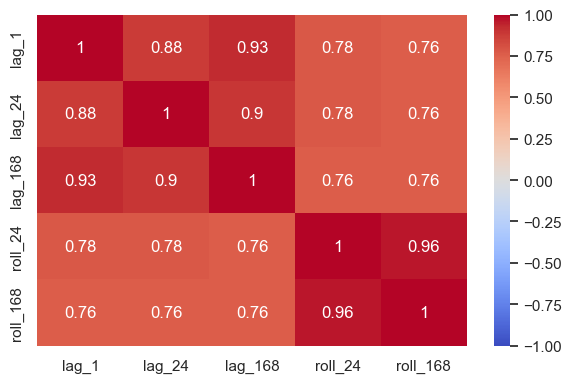

Koefisien terbesar: Lasso (interpretasikan sesuai transformasi)


,feature,coef,abs_coef
0,num__lag_1,24.6508,24.6508
1,num__lag_168,21.5896,21.5896
2,num__lag_24,8.3491,8.3491
3,num__is_holiday,-0.1932,0.1932
4,num__is_weekend,-0.1524,0.1524
5,num__roll_168,-0.0993,0.0993
6,num__day_of_week,-0.0712,0.0712
7,num__is_airport,-0.0101,0.0101
8,borough__PU_borough_Brooklyn,0.0000,0.0000
9,borough__PU_borough_Staten Island,0.0000,0.0000


In [8]:
LAG=['lag_1','lag_24','lag_168','roll_24','roll_168']
cor=train[LAG].corr()
display(cor.round(3))
fig,ax=plt.subplots(figsize=(6,4));sns.heatmap(cor,annot=True,cmap='coolwarm',vmin=-1,vmax=1,ax=ax)
plt.tight_layout();plt.savefig(OUT/'06b_lag_correlation.png',dpi=150);plt.show()

# Koefisien pada fitur numerik telah diskalakan; satuannya per 1 standar deviasi training.
# Koefisien hasil log1p berada pada skala log-target, sehingga tidak langsung berarti jumlah pickup.
for name, model in model_tersimpan.items():
    pipe = model.regressor_ if isinstance(model,TransformedTargetRegressor) else model
    core=pipe.named_steps['model'];pre=pipe.named_steps['preprocess']
    if hasattr(core,'coef_'):
        feature_names=pre.get_feature_names_out()
        coef=np.asarray(core.coef_).ravel()
        k=min(12,len(coef)); top=np.argsort(np.abs(coef))[-k:][::-1]
        table=pd.DataFrame({'feature':feature_names[top],'coef':coef[top], 'abs_coef':np.abs(coef[top])})
        table.to_csv(OUT/f'06b_coefficients_{name}.csv',index=False)
        if name==best_name:
            print('Koefisien terbesar:',name,'(interpretasikan sesuai transformasi)')
            display(table.round(4))


## 8. Ringkasan & serah-terima Fase 7

In [9]:
print('Model terbaik pada validation (sebelum tuning):',best_name)
print('Seasonal naive MAE:',round(base_result['mae'],4))
print('Model MAE:',round(eval_metrik(y_val,val_pred)['mae'],4))
print('File dihasilkan:',*[p.name for p in sorted(OUT.glob('06b_*'))],sep='\n- ')
print('JANGAN jalankan test Juni sekarang. Fase 7: tuning Ridge/Lasso hanya pada train.')


Model terbaik pada validation (sebelum tuning): Lasso
Seasonal naive MAE: 5.2773
Model MAE: 4.1556
File dihasilkan:
- 06b_coefficients_Lasso.csv
- 06b_coefficients_Lasso_log1p.csv
- 06b_coefficients_Linear.csv
- 06b_coefficients_Linear_log1p.csv
- 06b_coefficients_Ridge.csv
- 06b_coefficients_Ridge_log1p.csv
- 06b_diagnostics_validation.png
- 06b_lag_correlation.png
- 06b_metrics_validation.csv
- 06b_metrics_zona_ramai_sepi.csv
- 06b_predictions_validation.parquet
- 06b_train_validation_gap.csv
JANGAN jalankan test Juni sekarang. Fase 7: tuning Ridge/Lasso hanya pada train.


## 9. Evaluasi TEST FINAL -- terkunci secara default

In [10]:
if PAKAI_TEST_FINAL:
    # Hanya setelah keputusan model + hyperparameter final dicatat dan disetujui tim.
    # Gunakan konfigurasi model final yang telah dipilih; tidak menggunakan Juni untuk memilih model.
    final_name=best_name
    test=data[data.split=='test'].sort_values(['hour','zone_id']).copy()
    assert not test[FITUR+[TARGET]].isna().any().any()
    p_test=np.maximum(model_tersimpan[final_name].predict(test[FITUR]),0)
    scores=eval_metrik(test[TARGET].to_numpy(),p_test)
    print('TEST FINAL',final_name,scores)
    pd.DataFrame([{'model':final_name,'periode':'test',**scores}]).to_csv(OUT/'06b_metrics_test_FINAL.csv',index=False)
else:
    print('Test Juni dikunci. Ubah PAKAI_TEST_FINAL hanya setelah model final telah disepakati.')


Test Juni dikunci. Ubah PAKAI_TEST_FINAL hanya setelah model final telah disepakati.
